# Iris Flower Classification: Logistic Regression vs Decision Tree

## Objective
Build and evaluate two supervised classification models on the Iris dataset. The workflow includes exploratory data analysis, an 80/20 train-test split, feature standardization, classification metrics, confusion-matrix heatmaps, and a two-feature decision-boundary visualization.

**Models:** Logistic Regression and Decision Tree  
**Metrics:** Accuracy, precision, recall, and F1-score  
**Reproducibility:** A fixed random seed is used throughout.

> The primary models use all four flower measurements. The decision-boundary plots use only petal length and petal width so that the model regions can be displayed on a 2D graph.


## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 2. Load the Iris dataset

The notebook first attempts to read the supplied CSV dataset from the provided URL. If the URL is unavailable (for example, when working offline), it falls back to Scikit-Learn's built-in copy of the same benchmark dataset.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Loaded Iris dataset from the provided CSV URL.")
except Exception as error:
    iris = load_iris(as_frame=True)
    df = iris.frame.rename(columns={
        "sepal length (cm)": "sepal_length",
        "sepal width (cm)": "sepal_width",
        "petal length (cm)": "petal_length",
        "petal width (cm)": "petal_width",
        "target": "species"
    })
    df["species"] = df["species"].map(dict(enumerate(iris.target_names)))
    print("CSV URL unavailable; loaded Scikit-Learn's built-in Iris dataset.")

df.head()


CSV URL unavailable; loaded Scikit-Learn's built-in Iris dataset.


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Understand and explore the data

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()
print("\nMissing values per column:")
display(df.isnull().sum())
print("\nSpecies counts:")
display(df["species"].value_counts())


Dataset shape: (150, 5)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values per column:


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


Species counts:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [4]:
display(df.describe(include="all"))

,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


### Data quality checks

Check missing values, exact duplicate rows, and numeric feature validity. Duplicate rows are reported for review rather than automatically removed, so the benchmark data is not changed without justification.

In [5]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
print("Total missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

assert df[feature_cols].apply(pd.to_numeric, errors="coerce").notna().all().all(), "Feature columns must contain valid numeric values."
assert df["species"].notna().all(), "Target column contains missing values."
print("Data quality checks completed.")

Total missing values: 0
Duplicate rows: 1
Data quality checks completed.


### Pairplot

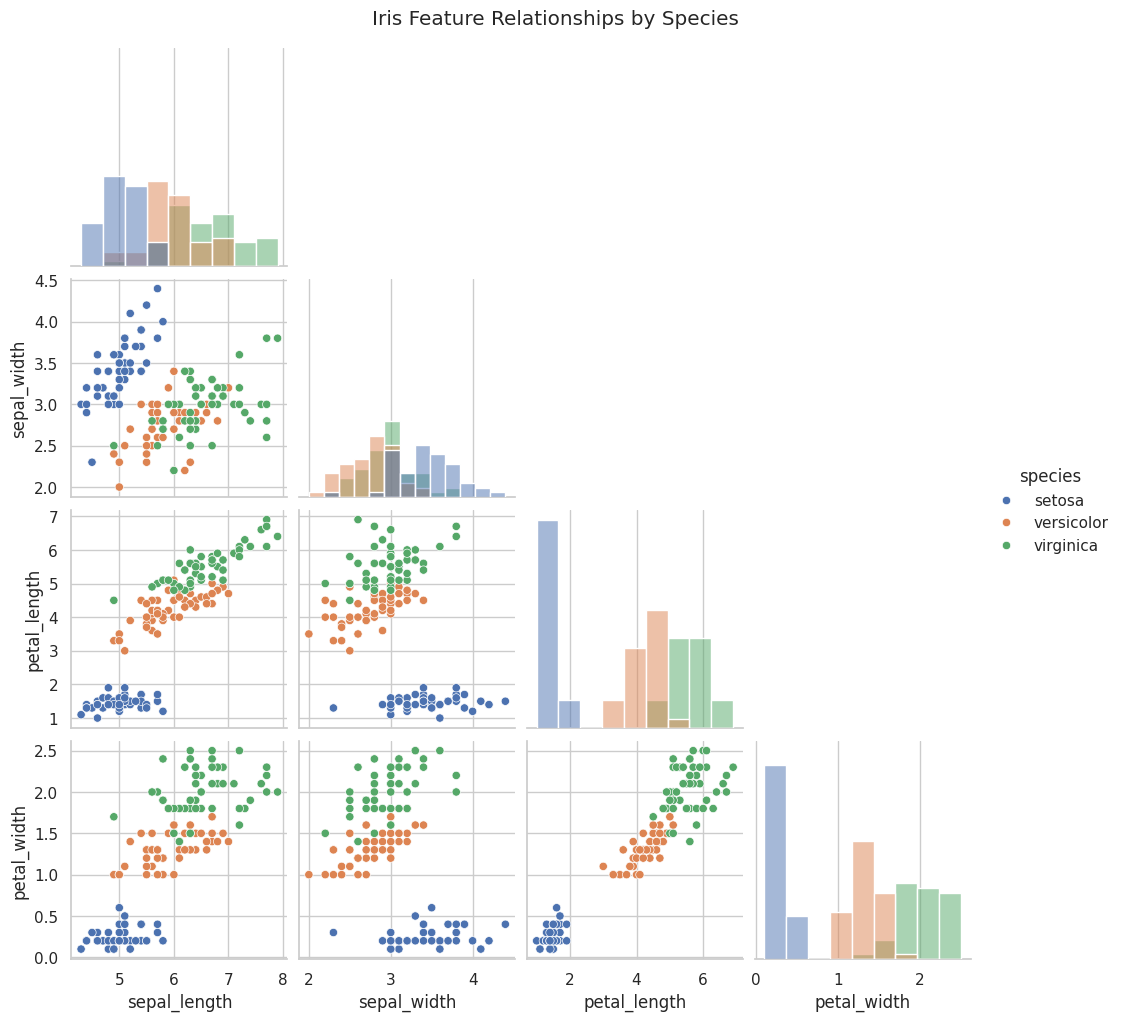

In [6]:
pair_grid = sns.pairplot(df, hue="species", diag_kind="hist", corner=True)
pair_grid.fig.suptitle("Iris Feature Relationships by Species", y=1.02)
pair_grid.fig.savefig(OUTPUT_DIR / "pairplot.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Prepare features and target

The four numeric measurements are the input features (`X`). The flower species is the target (`y`). The split keeps 80% of the rows for training and 20% for testing, while `stratify=y` preserves the class proportions in both sets.

In [7]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[feature_cols]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining class distribution:")
display(y_train.value_counts())


Training rows: 120
Testing rows: 30

Training class distribution:


species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

## 5. Build and train the models

**Important:** StandardScaler is placed inside a Scikit-Learn `Pipeline`. This means the scaler is fitted only on the training data, preventing information from the test set from leaking into training. Scaling is especially useful for Logistic Regression because it is sensitive to feature magnitudes. A Decision Tree does not require scaling, but it is included in the same consistent workflow here.

In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")


Logistic Regression trained successfully.
Decision Tree trained successfully.


## 6. Evaluate model performance

In [9]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


### Classification reports

Macro averages calculate each class's metric independently and then take the unweighted mean. This gives each Iris species equal importance.

In [10]:
for name, y_pred in predictions.items():
    print(f"\n{name} — Classification Report")
    print(classification_report(y_test, y_pred, zero_division=0))



Logistic Regression — Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree — Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 7. Confusion matrix heatmaps

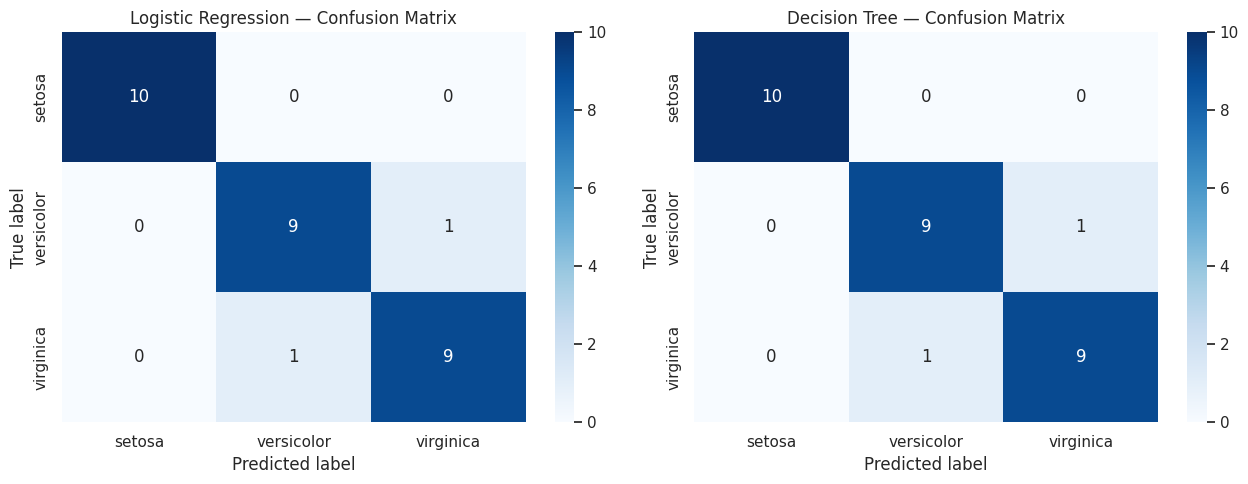

In [11]:
class_names = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names, ax=ax
    )
    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Compare the evaluation metrics

The chart below makes it easier to compare the two models across all four evaluation metrics.

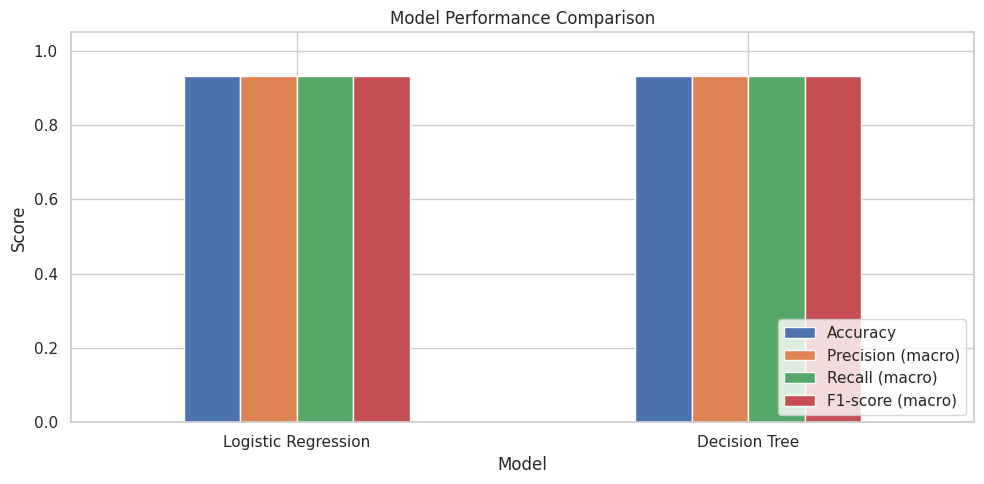

In [12]:
ax = results_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 9. Visualize decision boundaries (2D)

A decision boundary requires two input dimensions for a standard 2D plot. This section therefore trains additional visualization-only versions of each model using **petal length** and **petal width**. These are not the same fitted estimators used for the four-feature benchmark metrics above.

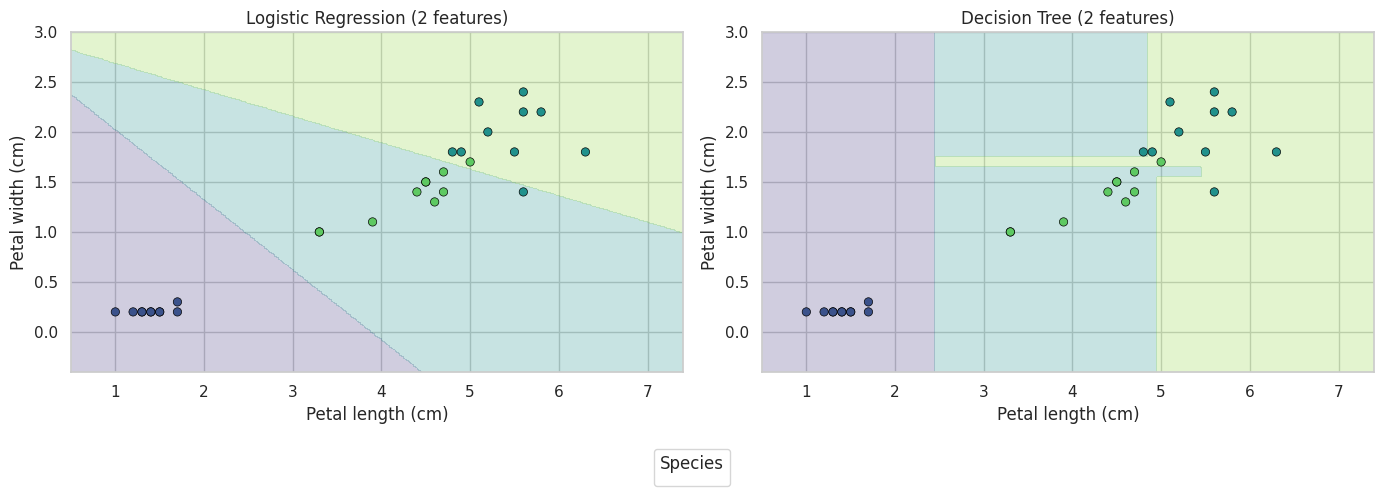

In [13]:
boundary_features = ["petal_length", "petal_width"]
X2 = df[boundary_features]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

boundary_models = {
    "Logistic Regression (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

for model in boundary_models.values():
    model.fit(X2_train, y2_train)

# Create a mesh over the observed feature ranges.
x_min, x_max = X2[boundary_features[0]].min() - 0.5, X2[boundary_features[0]].max() + 0.5
y_min, y_max = X2[boundary_features[1]].min() - 0.5, X2[boundary_features[1]].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=boundary_features
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, model) in zip(axes, boundary_models.items()):
    grid_pred = model.predict(grid)
    class_to_num = {label: i for i, label in enumerate(class_names)}
    zz = np.array([class_to_num[label] for label in grid_pred]).reshape(xx.shape)

    ax.contourf(xx, yy, zz, alpha=0.25, levels=np.arange(-0.5, len(class_names) + 0.5, 1), cmap="viridis")
    sns.scatterplot(
        data=pd.DataFrame({"petal_length": X2_test["petal_length"],
                           "petal_width": X2_test["petal_width"],
                           "species": y2_test}),
        x="petal_length", y="petal_width", hue="species",
        palette="viridis", edgecolor="black", ax=ax, legend=False
    )
    ax.set_title(name)
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Petal width (cm)")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Species", loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.10, 1, 1])
fig.savefig(OUTPUT_DIR / "decision_boundaries.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Conclusion

- Both classifiers were trained on the same stratified 80/20 train-test split.
- Accuracy measures the overall proportion of correct predictions.
- Precision measures how many predictions for a class were correct.
- Recall measures how many actual examples of a class were found.
- F1-score is the harmonic mean of precision and recall.
- The confusion matrices show which species are correctly classified and where errors occur.

Use the metric table and classification reports generated above to state which model performed better on this particular test split. Do not assume one model is always best: results can change with the split, model settings, and dataset.


### Result-based comparison

The following cell identifies the model with the highest test-set macro F1-score. Use the displayed metrics and confusion matrices to explain the result.

In [14]:
best_model = results_df["F1-score (macro)"].idxmax()
print(f"Best model by macro F1-score on this test split: {best_model}")
display(results_df.sort_values("F1-score (macro)", ascending=False).round(4))

Best model by macro F1-score on this test split: Logistic Regression


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


### Saved project outputs

Running this notebook from its project folder saves the pairplot, confusion-matrix heatmaps, model-comparison chart, and decision-boundary plots as high-resolution PNG files inside `outputs/`.